# 1. 数据读取

In [116]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/Online Retail.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


InvoiceNo：发票编号

StockCode：产品编号

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


可以看出大部分特征都没有缺失值，仅Description与Customer ID有部分缺失，考虑到Description列为商品描述，可以直接删去这一特征，同时删去Customer ID列有缺失值的数据。
InvoiceDate列的数据类型需要转换成datetime，以及Customer ID列需要转换成int类型

In [118]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


可以看出Quantity和UnitPrice列有小于0的异常值，直接删去这些数据（可能这些数据只是多写了负号，或者是取消的订单）

In [119]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [120]:
(df['UnitPrice'] < 0).sum()

np.int64(2)

In [121]:
df[df['UnitPrice'] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/11 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/11 14:52,-11062.06,NaN,United Kingdom


可以看出UnitPrice为负的行CusomerID也为Nan，因此可直接删去CustomerID缺失的行

In [122]:
df = df.dropna(subset='CustomerID')

In [123]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,406829.000000,406829.000000,406829.000000
mean,12.061303,3.460471,15287.690570
std,248.693370,69.315162,1713.600303
min,-80995.000000,0.000000,12346.000000
25%,2.000000,1.250000,13953.000000
50%,5.000000,1.950000,15152.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,38970.000000,18287.000000


发现此时出现了UnitPrice为0的行，后续也需要进行分析

In [124]:
df.nunique()

InvoiceNo      22190
StockCode       3684
Description     3896
Quantity         436
InvoiceDate    20460
UnitPrice        620
CustomerID      4372
Country           37
dtype: int64

In [125]:
# 重复值处理
df.duplicated().sum()
df = df.drop_duplicates()

In [126]:
df.duplicated().sum()

np.int64(0)

In [127]:
df.info()

<class 'pandas.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    401604 non-null  str    
 1   StockCode    401604 non-null  str    
 2   Description  401604 non-null  str    
 3   Quantity     401604 non-null  int64  
 4   InvoiceDate  401604 non-null  str    
 5   UnitPrice    401604 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      401604 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 27.6 MB


同时，根据数据集来源中的描述可知，InvoiceNo以C开头的为取消订单，可考虑单独列为二分类变量进行分析

# 2. 描述性分析

In [128]:
# 分析数量或单价为负数的记录
neg_df = df[df['Quantity'] < 0]
neg_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/10 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/10 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom


从上面可以观察到，数量为负的行，大概率对应的是取消的订单

In [129]:
neg_df['InvoiceNo'].count() == neg_df['InvoiceNo'].str.upper().str.match(r'^C').sum()

np.True_

这说明我们的判断是正确的，因此对于数量为负的列直接构造新的特征来标记订单是否被取消

In [130]:
# 分析UnitPrice为0的记录
zero_df = df[df['UnitPrice'] == 0]
zero_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12/5/10 14:02,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,12/16/10 14:36,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,12/21/10 13:45,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,1/6/11 16:41,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,1/6/11 16:41,0.0,13081.0,United Kingdom


In [131]:
zero_df.info()

<class 'pandas.DataFrame'>
Index: 40 entries, 9302 to 502122
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    40 non-null     str    
 1   StockCode    40 non-null     str    
 2   Description  40 non-null     str    
 3   Quantity     40 non-null     int64  
 4   InvoiceDate  40 non-null     str    
 5   UnitPrice    40 non-null     float64
 6   CustomerID   40 non-null     float64
 7   Country      40 non-null     str    
dtypes: float64(2), int64(1), str(5)
memory usage: 2.8 KB


In [132]:
# 检查这些商品是否在其他订单中有正常价格记录
zero_df['StockCode'].isin(df[df['UnitPrice'] > 0]['StockCode']).sum()

np.int64(40)

In [133]:
# 查看这些商品在其他订单中的正常价格记录
df[df['StockCode'].isin(zero_df['StockCode']) & (df['UnitPrice'] > 0)].describe()

,Quantity,UnitPrice,CustomerID
count,10534.000000,10534.000000,10534.000000
mean,8.920733,19.988274,15141.680938
std,36.540860,411.745733,1723.434310
min,-1350.000000,0.001000,12347.000000
25%,2.000000,2.080000,13695.000000
50%,4.000000,4.250000,15039.000000
75%,8.000000,8.500000,16639.000000
max,1600.000000,38970.000000,18287.000000


考虑到UnitPrice为0的行数量很少而且价格普遍偏低，这些订单可能是作为赠品。

# 3. 预处理

In [134]:
parts = df['InvoiceDate'].str.split('/', expand=True)
first = parts[0].astype(int)
second = parts[1].astype(int)

first.max(), second.max()

(np.int64(12), np.int64(31))

In [135]:
# 数据类型的转换
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%y %H:%M')
df['CustomerID'] = df['CustomerID'].astype(int)

In [136]:
df.info()

<class 'pandas.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  str           
 1   StockCode    401604 non-null  str           
 2   Description  401604 non-null  str           
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[us]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 27.6 MB


In [137]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [138]:
# 构造TotalPrice特征
df['TotalPrice'] = abs(df['Quantity'] * df['UnitPrice'])
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,401604.000000,401604,401604.000000,401604.000000,401604.000000
mean,12.183273,2011-07-10 12:08:23.848567,3.474064,15281.160818,23.644930
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000,0.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13939.000000,4.950000
50%,5.000000,2011-07-29 15:40:00,1.950000,15145.000000,11.900000
75%,12.000000,2011-10-20 11:58:30,3.750000,16784.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,168469.600000
std,250.283037,NaN,69.764035,1714.006089,430.196317


In [139]:
# 构造订单是否取消特征
df['cancelled'] = df['Quantity'] < 0
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,cancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


In [140]:
df.to_csv('data/processed_data.csv', index=False)

# 4. EDA

In [141]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,cancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


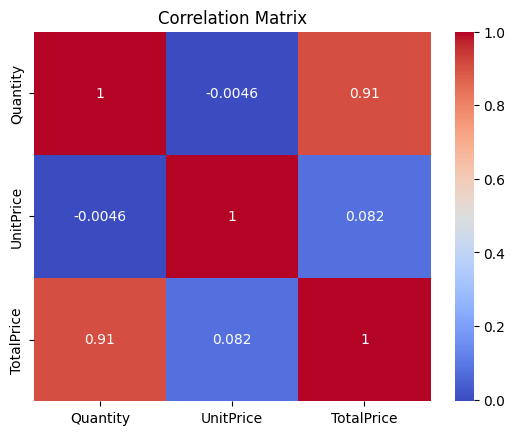

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

df_view = df[df['Quantity'] > 0]
corr = df_view[['Quantity', 'UnitPrice', 'TotalPrice']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

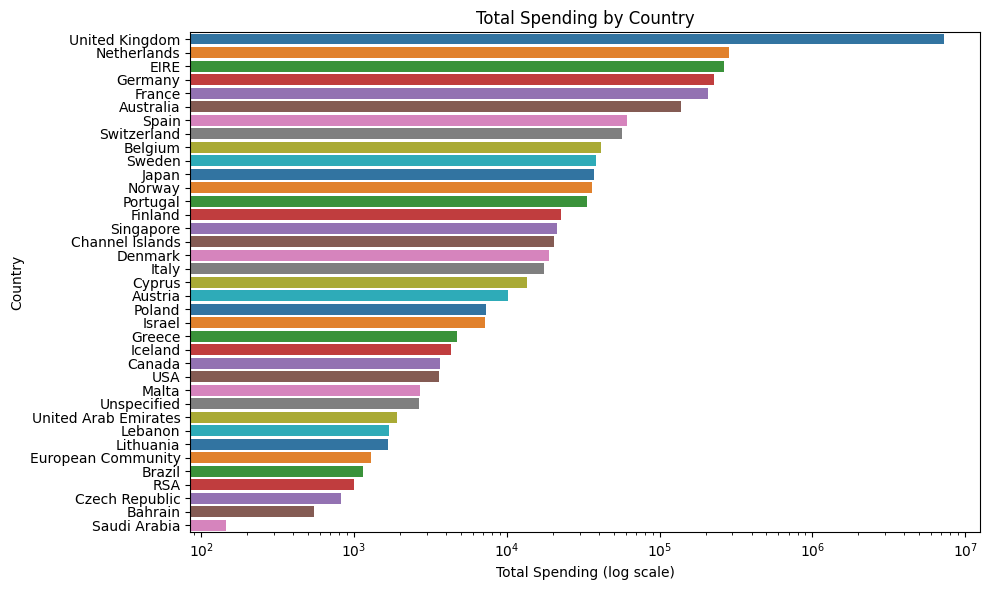

In [143]:
# 不同国家的GMV
country_gmv = df_view.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=country_gmv.values, 
    y=country_gmv.index, 
    hue=country_gmv.index,
    palette='tab10',
    dodge=False,
    legend=False
)
plt.xscale('log')
plt.title('Total Spending by Country')
plt.xlabel('Total Spending (log scale)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

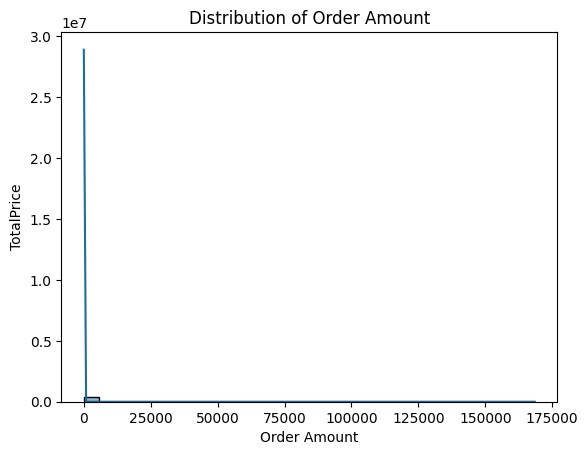

<Figure size 1000x600 with 0 Axes>

In [144]:
# 订单金额分布
sns.histplot(df_view['TotalPrice'], bins=30, kde=True, color="#1e6e9abc")

plt.title('Distribution of Order Amount')
plt.xlabel('Order Amount')
plt.ylabel('TotalPrice')
plt.figure(figsize=(10, 6))

In [145]:
# 销量前十的商品
product_amount = df_view.groupby(['StockCode', 'Description'])['Quantity'].sum().nlargest(10)
product_amount

StockCode  Description                       
23843      PAPER CRAFT , LITTLE BIRDIE           80995
23166      MEDIUM CERAMIC TOP STORAGE JAR        77916
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
85099B     JUMBO BAG RED RETROSPOT               46078
85123A     WHITE HANGING HEART T-LIGHT HOLDER    36706
84879      ASSORTED COLOUR BIRD ORNAMENT         35263
21212      PACK OF 72 RETROSPOT CAKE CASES       33670
22197      POPCORN HOLDER                        30919
23084      RABBIT NIGHT LIGHT                    27153
22492      MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

In [146]:
# 取消订单率前十的商品
product_stats = df.groupby(['StockCode', 'Description']).agg(
    total_orders=('cancelled', 'size'),     
    cancelled_orders=('cancelled', 'sum')    
).reset_index()

product_stats['cancel_rate'] = (product_stats['cancelled_orders'] / product_stats['total_orders'])

# 过滤掉样本量太少的商品
min_orders = 20
product_stats = product_stats[product_stats['total_orders'] >= min_orders]

top10_cancel = product_stats.sort_values('cancel_rate', ascending=False).head(10)
top10_cancel

,StockCode,Description,total_orders,cancelled_orders,cancel_rate
3911,D,Discount,77,77,1.000000
3913,M,Manual,460,175,0.380435
1983,23064,CINDERELLA CHANDELIER,32,10,0.312500
1549,22656,VINTAGE BLUE KITCHEN CABINET,26,6,0.230769
1114,22198,LARGE POPCORN HOLDER,68,15,0.220588
2448,23462,ROCOCO WALL MIRROR WHITE,55,12,0.218182
1359,22461,SAVOY ART DECO CLOCK,57,12,0.210526
1994,23071,MARIE ANTOINETTE TRINKET BOX GOLD,21,4,0.190476
577,21424,WOODLAND STORAGE BOX LARGE,27,5,0.185185
3509,85159B,"WHITE TEA,COFFEE,SUGAR JARS",72,13,0.180556


In [147]:
# 复购率前十的商品
customer_product = df_view.groupby(['StockCode', 'CustomerID']).agg(purchase_count=('InvoiceNo', 'nunique')).reset_index()

customer_product['is_repeat'] = customer_product['purchase_count'] > 1

product_repeat = customer_product.groupby('StockCode').agg(
    total_customers=('CustomerID', 'nunique'),  
    repeat_customers=('is_repeat', 'sum')        
).reset_index()

product_repeat['repeat_rate'] = (
    product_repeat['repeat_customers'] / product_repeat['total_customers']
)

min_customers = 20
product_repeat = product_repeat[
    product_repeat['total_customers'] >= min_customers
]

top10_repeat = product_repeat.sort_values(
    'repeat_rate', ascending=False
).head(10)

product_desc = df_view.groupby('StockCode')['Description'].first().reset_index()
top10_repeat = top10_repeat.merge(product_desc, on='StockCode', how='left')
top10_repeat

,StockCode,total_customers,repeat_customers,repeat_rate,Description
0,POST,331,189,0.570997,POSTAGE
1,22383,434,226,0.520737,LUNCH BAG SUKI DESIGN
2,20725,532,276,0.518797,LUNCH BAG RED RETROSPOT
3,20726,372,187,0.502688,LUNCH BAG WOODLAND
4,20727,458,229,0.500000,LUNCH BAG BLACK SKULL.
5,23204,199,99,0.497487,CHARLOTTE BAG APPLES DESIGN
6,22197,407,200,0.491400,SMALL POPCORN HOLDER
7,85099B,635,312,0.491339,JUMBO BAG RED RETROSPOT
8,22727,388,188,0.484536,ALARM CLOCK BAKELIKE RED
9,22726,322,156,0.484472,ALARM CLOCK BAKELIKE GREEN


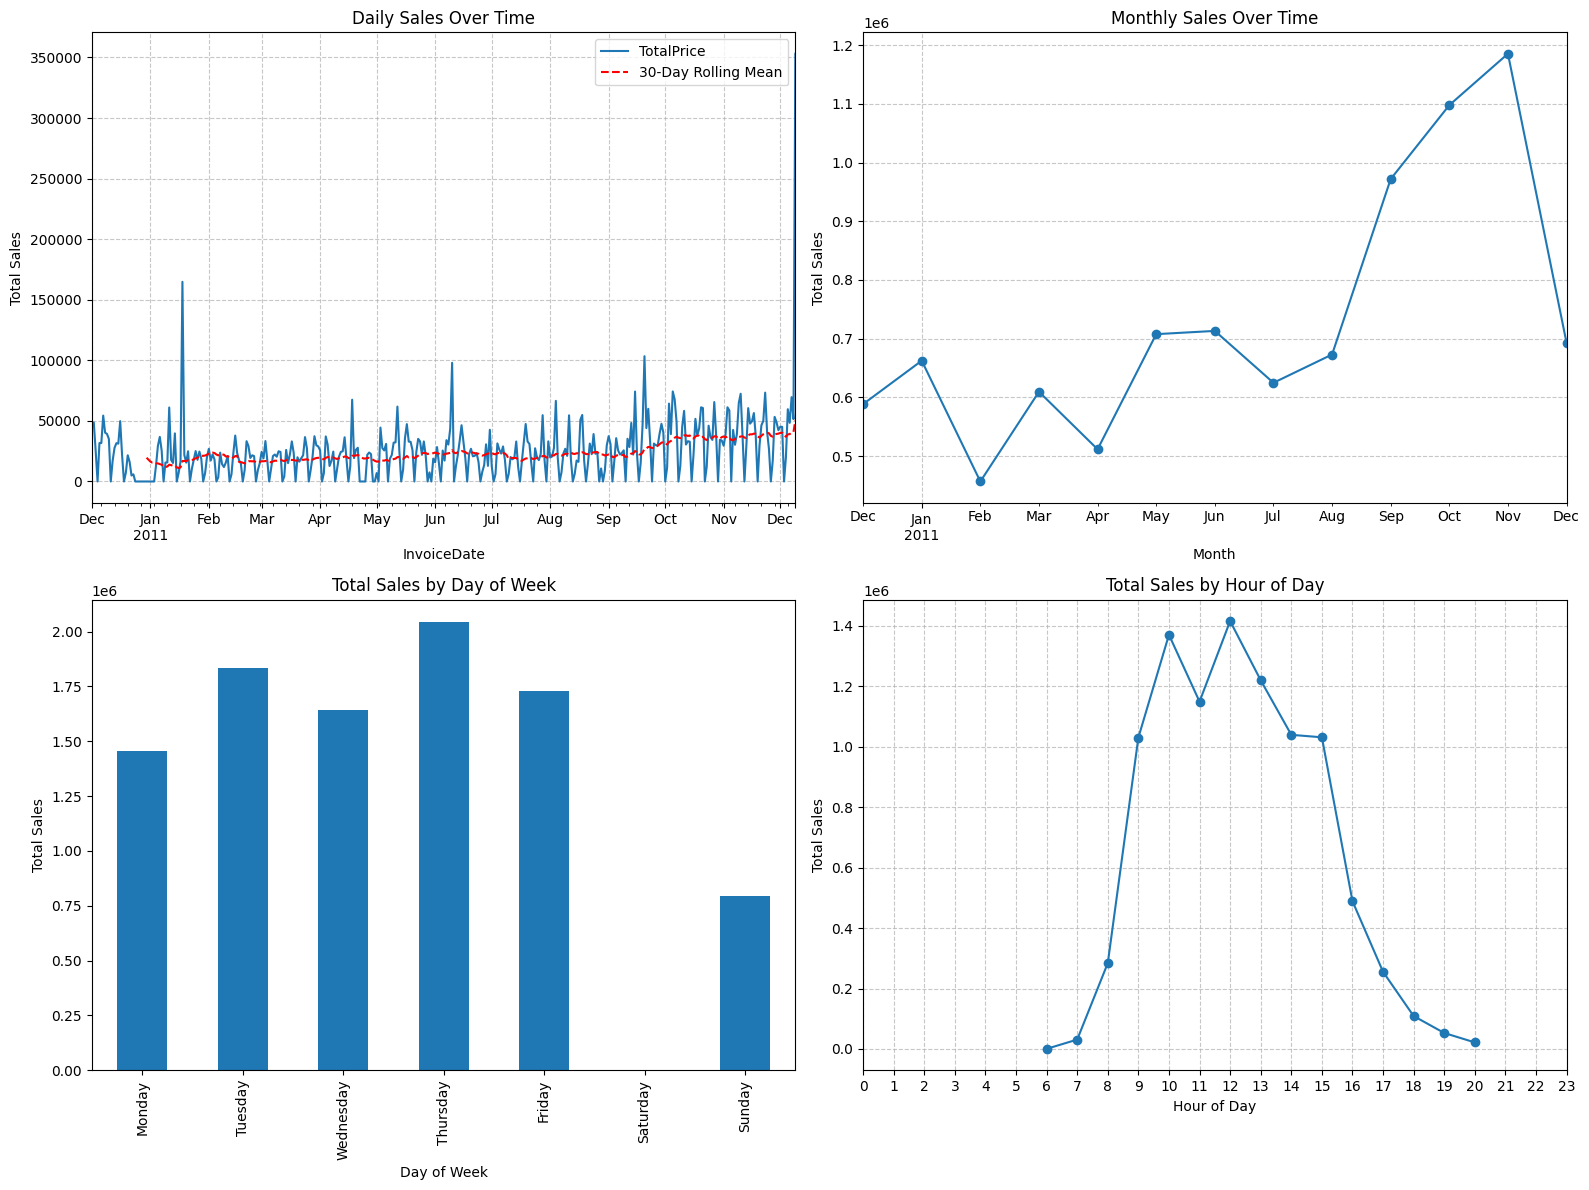

In [148]:
# 销售金额随时间的变化
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

daily_sales = df.set_index('InvoiceDate')['TotalPrice'].resample('D').sum()
daily_sales.plot(ax=axes[0,0], title='Daily Sales Over Time',
                 ylabel='Total Sales',
                 xlabel='Date')
daily_sales.rolling(window=30).mean().plot(ax=axes[0,0], label='30-Day Rolling Mean', color='red', linestyle='--')
axes[0,0].grid(True, linestyle='--', alpha=0.7)
axes[0,0].legend()

df.set_index('InvoiceDate')['TotalPrice'].resample('ME').sum().plot(ax=axes[0,1], marker='o')
axes[0,1].set(title='Monthly Sales Over Time',
              ylabel='Total Sales',
              xlabel='Month')
axes[0,1].grid(True, linestyle='--', alpha=0.7)

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df.groupby(df['InvoiceDate'].dt.day_name())['TotalPrice'].sum().reindex(day_order).plot(kind='bar', ax=axes[1,0])
axes[1,0].set(title='Total Sales by Day of Week',
              ylabel='Total Sales',
              xlabel='Day of Week')

df.groupby(df['InvoiceDate'].dt.hour)['TotalPrice'].sum().plot(kind='line', marker='o', ax=axes[1,1])
axes[1,1].set(title='Total Sales by Hour of Day',
              ylabel='Total Sales',
              xlabel='Hour of Day',
              xticks=range(0, 24))
axes[1,1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()